# Three decode paths: memory and speed

| script | path | needs |
|---|---|---|
| `run_vllm.py` | vLLM server over HTTP | server **UP** |
| `run_generate.py` | `model.generate(output_logits=True)` | server **DOWN** |
| `run_manual.py` | hand-written decode loop | server **DOWN** |

Each writes `results/<path>.json`. They are separate processes because the server
reserves VRAM at startup, so it cannot be up while the in-process paths run.

```
# with a vLLM server up (e.g. dxo-orchestration: docker compose --profile gpu up -d)
python run_vllm.py

# with every vLLM server stopped
python run_generate.py
python run_manual.py
```

**Read the memory column carefully.** `decode_mib` = peak allocator high-water mark
minus the level before decoding (i.e. the weights). That isolates what decoding cost
— but only for the two in-process paths. vLLM's allocator is in another process and
claims its slab at startup, so its number is an nvidia-smi sample, not a comparable
peak. Speed is comparable across all three: same model, same prompt, greedy decoding.

In [2]:
import json
from pathlib import Path

RESULTS = Path("results")  # sits next to this notebook
ORDER = ["vllm", "generate", "manual"]

data = {p.stem: json.loads(p.read_text()) for p in RESULTS.glob("*.json")}
found = [k for k in ORDER if k in data]
missing = [k for k in ORDER if k not in data]

for key in found:
    meta = data[key]["meta"]
    print(f"{key:<9} {data[key]['label']:<34} model={data[key]['model']}")
    print(f"{'':<9} saved {meta['saved_at']}  decoding={meta.get('decoding')}")
    if meta.get("other_gpu_mib_at_start"):
        print(f"{'':<9} NOTE other processes held {meta['other_gpu_mib_at_start']:.0f} MiB")
if missing:
    print(f"\nnot run yet: {missing}  (the cells below just skip them)")

vllm      vLLM server (HTTP)                 model=local
          saved 2026-10-03 18:16:28  decoding=greedy
generate  generate() + output_logits         model=Qwen/Qwen3-4B-FP8
          saved 2026-10-03 18:17:29  decoding=greedy
          NOTE other processes held 4218 MiB
manual    manual loop (reduce in-loop)       model=Qwen/Qwen3-4B-FP8
          saved 2026-10-03 18:26:01  decoding=greedy
          NOTE other processes held 4218 MiB


## Speed

All three generate the same tokens (greedy), so tokens/sec is directly comparable.

In [3]:
budgets = sorted({r["budget"] for key in found for r in data[key]["runs"]})


def cell(key, budget, field):
    for run in data[key]["runs"]:
        if run["budget"] == budget:
            return run.get(field)
    return None


def table(field, unit, fmt="{:.1f}"):
    head = f"{'budget':>7} " + " ".join(f"{k:>14}" for k in found)
    print(head)
    print("-" * len(head))
    for budget in budgets:
        row = f"{budget:>7} "
        for key in found:
            value = cell(key, budget, field)
            row += f"{fmt.format(value) if value is not None else '-':>14} "
        print(row)
    print(f"({unit})")


table("tok_per_s", "tokens per second, higher is better")
print()
table("latency_s", "wall seconds for the whole request", "{:.2f}")

 budget           vllm       generate         manual
----------------------------------------------------
     32          154.9           49.7           49.9 
    128          157.1           49.4           50.1 
    512          157.6           49.4           50.0 
(tokens per second, higher is better)

 budget           vllm       generate         manual
----------------------------------------------------
     32           0.21           0.64           0.64 
    128           0.81           2.59           2.55 
    512           3.25          10.36          10.25 
(wall seconds for the whole request)


## Memory

`decode_mib` is what decoding cost on top of the weights. The question is how it
scales with the number of steps.

In [4]:
table("decode_mib", "MiB above the weights; vLLM's is cross-process, see note below")

if "generate" in found and "manual" in found:
    print("\ngenerate() minus manual loop, and what one logit row costs:")
    vocab = data["manual"]["meta"]["vocab"]
    print(f"    {'budget':>7} {'extra MiB':>11} {'per step':>10} {'fp32 row':>10}")
    for budget in budgets:
        g, m = cell("generate", budget, "decode_mib"), cell("manual", budget, "decode_mib")
        if g is None or m is None:
            continue
        steps = cell("manual", budget, "tokens") or 1
        print(f"    {budget:>7} {g - m:>11.1f} {(g - m) / steps:>10.3f} {vocab * 4 / 2**20:>10.3f}")
    print("\n'per step' landing on 'fp32 row' is the mechanism: generate() keeps one")
    print("full-vocab float32 logit row per step until the loop ends.")

 budget           vllm       generate         manual
----------------------------------------------------
     32            0.0           29.0           15.7 
    128            0.0           98.1           24.8 
    512            0.0          406.6          125.5 
(MiB above the weights; vLLM's is cross-process, see note below)

generate() minus manual loop, and what one logit row costs:
     budget   extra MiB   per step   fp32 row
         32        13.3      0.417      0.580
        128        73.3      0.573      0.580
        512       281.1      0.549      0.580

'per step' landing on 'fp32 row' is the mechanism: generate() keeps one
full-vocab float32 logit row per step until the loop ends.


In [5]:
# Both in-process paths also pay for the KV cache, which grows with sequence length
# no matter how the loop is written. Separating the two terms is what makes the
# comparison honest: only the logits term differs between the paths.
if "manual" in found:
    meta = data["manual"]["meta"]
    n_prompt = meta["prompt_tokens"]
    print(f"{'budget':>7} {'seq len':>8} {'manual decode':>14} {'of which KV*':>13}")
    for budget in budgets:
        m = cell("manual", budget, "decode_mib")
        if m is None:
            continue
        seq = n_prompt + (cell("manual", budget, "tokens") or 0)
        # Qwen3-4B: 36 layers, 8 KV heads, head_dim 128, bf16 -> 2 bytes.
        kv = 36 * 2 * 8 * 128 * seq * 2 / 2**20
        print(f"{budget:>7} {seq:>8} {m:>14.1f} {kv:>13.1f}")
    print("\n*computed from the architecture, not measured. The remainder is transient")
    print(" activations plus allocator slack.")

 budget  seq len  manual decode  of which KV*
     32       63           15.7           8.9
    128      159           24.8          22.4
    512      543          125.5          76.4

*computed from the architecture, not measured. The remainder is transient
 activations plus allocator slack.


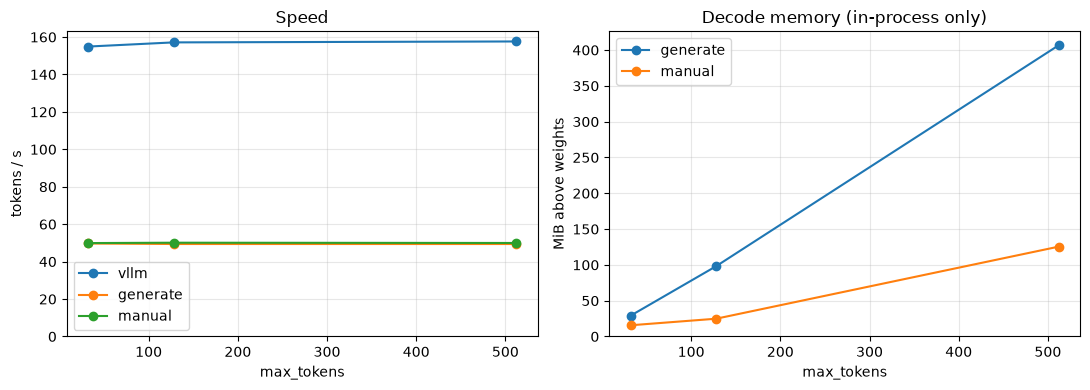

In [6]:
import matplotlib.pyplot as plt

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for key in found:
    runs = [r for r in data[key]["runs"] if r.get("tok_per_s")]
    left.plot([r["budget"] for r in runs], [r["tok_per_s"] for r in runs], "o-", label=key)
    mem = [r for r in data[key]["runs"] if r.get("decode_mib") is not None]
    if key != "vllm":  # cross-process number, not on the same axis
        right.plot([r["budget"] for r in mem], [r["decode_mib"] for r in mem], "o-", label=key)

left.set(xlabel="max_tokens", ylabel="tokens / s", title="Speed")
left.set_ylim(bottom=0)
right.set(xlabel="max_tokens", ylabel="MiB above weights", title="Decode memory (in-process only)")
right.set_ylim(bottom=0)
for axis in (left, right):
    axis.grid(alpha=0.3)
    axis.legend()
plt.tight_layout()
plt.show()

## Why vLLM's memory number is not on the same axis

vLLM claims `--gpu-memory-utilization` of the card when it starts and works inside
that slab, mostly as KV cache. So its per-request delta is ~0 — which is not vLLM
winning the memory comparison, it is the cost being paid up front and becoming
invisible per request. `run_vllm.py` samples the server process with nvidia-smi and
records the caveat in its own `meta`.

The comparison vLLM genuinely contributes here is speed.

In [7]:
if "vllm" in found:
    meta = data["vllm"]["meta"]
    print(f"server pid {meta.get('server_pid')}  fingerprint {meta.get('fingerprint')}")
    print(f"caveat: {meta.get('memory_caveat')}")
    for run in data["vllm"]["runs"]:
        print(
            f"  budget={run['budget']:>4} server held {run['baseline_mib']} -> "
            f"{run['peak_mib']} MiB  (delta {run['decode_mib']})"
        )
else:
    print("run_vllm.py has not been run; start the server and run it to fill this in.")

server pid 287131  fingerprint vllm-0.30.0-8d95730e
caveat: cross-process: nvidia-smi sampling, not a torch allocator peak
  budget=  32 server held 9860.0 -> 9860.0 MiB  (delta 0.0)
  budget= 128 server held 9860.0 -> 9860.0 MiB  (delta 0.0)
  budget= 512 server held 9860.0 -> 9860.0 MiB  (delta 0.0)


In [8]:
from __future__ import annotations

import json
import platform
import time
from pathlib import Path

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

In [9]:
PATH = "manual"
LABEL = "manual loop (reduce in-loop)"
MODEL = "Qwen/Qwen3-4B-FP8"
PROMPT = "Count from 1 to 300, separated by commas. Do not stop early."
BUDGETS = (32, 128, 512)
TOP_LOGPROBS = 3
# RESULTS = Path(__file__).parent / "results"

In [10]:
import os
import subprocess

out = subprocess.run(
    ["nvidia-smi", "--query-compute-apps=pid,used_gpu_memory", "--format=csv,noheader,nounits"],
    capture_output=True,
    text=True,
    check=False,
).stdout
mine, total = os.getpid(), 0.0
for line in out.strip().splitlines():
    if not line.strip():
        continue
    pid_text, mib_text = (part.strip() for part in line.split(","))
    if int(pid_text) != mine:
        total += float(mib_text)

In [11]:
print(f"other processes hold {total:.0f} MiB on this GPU")
if total > 500:
    print("  WARNING: the card is shared. Peaks will be skewed and a long run may OOM.")

other processes hold 4222 MiB on this GPU


In [12]:
tok = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForCausalLM.from_pretrained(MODEL, dtype="auto", device_map="cuda").eval()

eos = model.generation_config.eos_token_id
eos_ids = frozenset(eos if isinstance(eos, (list, tuple)) else [eos])

Loading weights:   0%|          | 0/651 [00:00<?, ?it/s]

In [13]:
model.generation_config

GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "temperature": 0.6,
  "top_k": 20,
  "top_p": 0.95
}

In [14]:
prompt = tok.apply_chat_template(
    [{"role": "user", "content": PROMPT}],
    add_generation_prompt=True,
    tokenize=False,
    enable_thinking=False,
)
enc = tok(prompt, return_tensors="pt").to(model.device)
n_prompt = int(enc.input_ids.shape[1])

In [15]:
meta = {
        "prompt_tokens": n_prompt,
        "vocab": int(model.config.vocab_size),
        "dtype": str(model.dtype),
        "decoding": "greedy",
        "other_gpu_mib_at_start": total,
        "torch": torch.__version__,
        "gpu": torch.cuda.get_device_name(0),
        "host": platform.node(),
        "saved_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    }

In [16]:
def other_gpu_mib() -> float:
    """GPU memory held by OTHER processes.

    Worth printing before measuring: a Jupyter kernel or a stray server sharing
    the card both skews the peak and can OOM a long run outright. The number goes
    into the result file so a surprising measurement can be explained later.
    """
    import os
    import subprocess

    out = subprocess.run(
        ["nvidia-smi", "--query-compute-apps=pid,used_gpu_memory", "--format=csv,noheader,nounits"],
        capture_output=True,
        text=True,
        check=False,
    ).stdout
    mine, total = os.getpid(), 0.0
    for line in out.strip().splitlines():
        if not line.strip():
            continue
        pid_text, mib_text = (part.strip() for part in line.split(","))
        if int(pid_text) != mine:
            total += float(mib_text)
    return total

In [17]:
import math

In [18]:
cur, cache = enc.input_ids, None
token_ids: list[int] = []
steps: list[dict] = []

print("init_cur: ",cur)

with torch.inference_mode():
    out = model(
        input_ids=cur, past_key_values=cache, use_cache=True, logits_to_keep=1
    )
    print("out: ",out)
    print("logit_shape: ",out.logits.shape)
    print("past_key_values_shape: ",len(out.past_key_values), out.past_key_values)
    print("past_key_values: ",out.past_key_values)
    cache = out.past_key_values
    logits = out.logits[0, -1].float()  # only the last position predicts
    print("logits: ",logits.shape)
    print(logits.argmax())
    chosen = int(logits.argmax())  # greedy
    print(tok.convert_ids_to_tokens([chosen]))
    logprobs = torch.log_softmax(logits.float(), dim=-1)
    print(logprobs)
    probs = logprobs.exp()
    values, ids = logprobs.topk(TOP_LOGPROBS)
    step_i = {
        "token": tok.decode([chosen]),
        "logprob": float(logprobs[chosen]),
        "entropy": float(-(probs * logprobs).nansum()),
        "top": [
            (tok.decode([int(t)]), float(v))
            for v, t in zip(values.tolist(), ids.tolist(), strict=True)
        ],
    }
    print("token: ",repr(step_i['token']))
    for v, t in zip(values.tolist(), ids.tolist()):
        print(f"{t:>7} {repr(tok.decode([t])):>12}  logprob={v:7.3f}  p={math.exp(v):.4f}")
    steps.append(step_i)
    del out, logits  # <-- the whole point: one row resident, not `budget` rows

    token_ids.append(chosen)
    #if chosen in eos_ids:
    #    break
    cur = torch.tensor([[chosen]], device=model.device, dtype=cur.dtype)
    print("cur_i: ",cur)

init_cur:  tensor([[151644,    872,    198,   2507,    504,    220,     16,    311,    220,
             18,     15,     15,     11,  18663,    553,  76602,     13,   3155,
            537,   2936,   4124,     13, 151645,    198, 151644,  77091,    198,
         151667,    271, 151668,    271]], device='cuda:0')


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

out:  CausalLMOutputWithPast(loss=None, logits=tensor([[[ 8.8750, 16.3750, 11.6250,  ...,  2.7344,  2.7344,  2.7344]]],
       device='cuda:0', dtype=torch.bfloat16), past_key_values=DynamicCache(layers=[DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer]), hidden_states=None, attentions=None)
logit_shape:  torch.Size([1, 1, 151936])
past_key_values_shape:  36 DynamicCache(layers=[DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLay

In [19]:
k = cache.layers[0].keys
v = cache.layers[0].values
print(len(cache), k.shape, v.shape, k.dtype)

36 torch.Size([1, 8, 31, 128]) torch.Size([1, 8, 31, 128]) torch.bfloat16


In [20]:
import inspect
print(model)                                    # 위 구조 그대로
print(inspect.getsource(type(model.model.layers[0]).forward))   # residual 코드
h = model.model(**enc, output_hidden_states=True).hidden_states
print(len(h), h[0].shape)                       # 37, (1, 31, 2560)  ← 임베딩 + 36층

Qwen3ForCausalLM(
  (model): Qwen3Model(
    (embed_tokens): Embedding(151936, 2560)
    (layers): ModuleList(
      (0-35): 36 x Qwen3DecoderLayer(
        (self_attn): Qwen3Attention(
          (q_proj): FP8Linear(in_features=2560, out_features=4096, bias=False)
          (k_proj): FP8Linear(in_features=2560, out_features=1024, bias=False)
          (v_proj): FP8Linear(in_features=2560, out_features=1024, bias=False)
          (o_proj): FP8Linear(in_features=4096, out_features=2560, bias=False)
          (q_norm): Qwen3RMSNorm((128,), eps=1e-06)
          (k_norm): Qwen3RMSNorm((128,), eps=1e-06)
        )
        (mlp): Qwen3MLP(
          (gate_proj): FP8Linear(in_features=2560, out_features=9728, bias=False)
          (up_proj): FP8Linear(in_features=2560, out_features=9728, bias=False)
          (down_proj): FP8Linear(in_features=9728, out_features=2560, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen3RMSNorm((2560,), eps=1e-06)
        

In [35]:
import torch
from transformers.masking_utils import create_causal_mask
from transformers.cache_utils import DynamicCache

inner, lm_head = model.model, model.lm_head   # Qwen3Model, Linear(2560→151936)

with torch.inference_mode():
    ids = enc.input_ids                 # (1, 31)
    S = ids.shape[1]

    # 1) 토큰 ID → 2560차원 벡터. 여기까진 위치 정보 없음
    h = inner.embed_tokens(ids)                                    # (1, 31, 2560)

    # 2) 위치 인덱스와 RoPE 테이블(cos, sin). 어텐션 안에서 Q·K를 회전시킬 때 쓰임
    pos = torch.arange(S, device=h.device).unsqueeze(0)          # (1, 31)
    print("pos: ",pos)
    pos_emb = inner.rotary_emb(h, pos)

    # 3) 인과 마스크 — 각 위치가 자기 이전만 보도록. 빼먹으면 미래를 훔쳐봅니다
    cache = DynamicCache(config=model.config)
    mask = create_causal_mask(config=model.config, inputs_embeds=h,
                              attention_mask=None, past_key_values=cache,
                              position_ids=pos)


    # 4) 36개 블록을 순서대로. h가 들어가서 h가 나오는 게 전부 — 폭은 계속 2560
    traj = [h]
    for layer in inner.layers:
        h = layer(h, attention_mask=mask, position_embeddings=pos_emb,
                  position_ids=pos, past_key_values=cache, use_cache=True)
        traj.append(h)
        print([None if l.keys is None else tuple(l.keys.shape) for l in cache.layers])

    # 5) 마지막 정규화 + 어 큰을 예측
    h = inner.norm(h)
    logits = lm_head(h[:, -1:, :]).float()                         # (1, 1, 151936)

chosen = int(logits[0, -1].argmax())
print("token:", repr(tok.decode([chosen])), "| id:", chosen)
print("traj:", len(traj), traj[0].shape, "| cache:", len(cache), cache.layers[0].keys.shape)

pos:  tensor([[ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
         18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]], device='cuda:0')
[(1, 8, 31, 128), None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None]
[(1, 8, 31, 128), (1, 8, 31, 128), None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None]
[(1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None]
[(1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), None, None, None, None, None, None, None, None,

In [33]:
create_causal_mask??

Signature:
create_causal_mask(
    config: transformers.configuration_utils.PreTrainedConfig,
    inputs_embeds: torch.Tensor,
    attention_mask: torch.Tensor | None,
    past_key_values: transformers.cache_utils.Cache | None,
    position_ids: torch.Tensor | None = None,
    or_mask_function: collections.abc.Callable | None = None,
    and_mask_function: collections.abc.Callable | None = None,
    block_sequence_ids: torch.Tensor | None = None,
    layer_idx: int | None = None,
    allow_is_causal_skip: bool = True,
) -> torch.Tensor | torch.nn.attention.flex_attention.BlockMask | None
Source:   
def create_causal_mask(
    config: PreTrainedConfig,
    inputs_embeds: torch.Tensor,
    attention_mask: torch.Tensor | None,
    past_key_values: Cache | None,
    position_ids: torch.Tensor | None = None,
    or_mask_function: Callable | None = None,
    and_mask_function: Callable | None = None,
    block_sequence_ids: torch.Tensor | None = None,
    layer_idx: int | None = None,
    al

In [22]:
DynamicCache??

Init signature:
DynamicCache(
    ddp_cache_data: collections.abc.Iterable[tuple[torch.Tensor | None, ...]] | None = None,
    config: transformers.configuration_utils.PreTrainedConfig | None = None,
    offloading: bool = False,
    offload_only_non_sliding: bool = False,
)
Source:        
class DynamicCache(Cache):
    """
    A cache that grows dynamically as more tokens are generated. This is the default for generative models.
    It stores the key and value states as a list of `CacheLayer`, one for each layer. The expected shape for each tensor
    in the `CacheLayer`s is `[batch_size, num_heads, seq_len, head_dim]`.
    If a config is passed, it will additionally check for sliding or hybrid cache structure, greatly reducing the
    memory requirement of the cached tensors to `[batch_size, num_heads, min(seq_len, sliding_window), head_dim]`.

    See `Cache` for details on common methods that are implemented by all cache classes.

    Args:
        ddp_cache_data (`Iterable[tuple[

In [23]:
inner.layers[0]

Qwen3DecoderLayer(
  (self_attn): Qwen3Attention(
    (q_proj): FP8Linear(in_features=2560, out_features=4096, bias=False)
    (k_proj): FP8Linear(in_features=2560, out_features=1024, bias=False)
    (v_proj): FP8Linear(in_features=2560, out_features=1024, bias=False)
    (o_proj): FP8Linear(in_features=4096, out_features=2560, bias=False)
    (q_norm): Qwen3RMSNorm((128,), eps=1e-06)
    (k_norm): Qwen3RMSNorm((128,), eps=1e-06)
  )
  (mlp): Qwen3MLP(
    (gate_proj): FP8Linear(in_features=2560, out_features=9728, bias=False)
    (up_proj): FP8Linear(in_features=2560, out_features=9728, bias=False)
    (down_proj): FP8Linear(in_features=9728, out_features=2560, bias=False)
    (act_fn): SiLUActivation()
  )
  (input_layernorm): Qwen3RMSNorm((2560,), eps=1e-06)
  (post_attention_layernorm): Qwen3RMSNorm((2560,), eps=1e-06)
)

In [24]:
pos

tensor([[ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
         18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]], device='cuda:0')

In [25]:
ids

tensor([[151644,    872,    198,   2507,    504,    220,     16,    311,    220,
             18,     15,     15,     11,  18663,    553,  76602,     13,   3155,
            537,   2936,   4124,     13, 151645,    198, 151644,  77091,    198,
         151667,    271, 151668,    271]], device='cuda:0')

In [26]:
inner.embed_tokens

Embedding(151936, 2560)

In [27]:
model.config

Qwen3Config {
  "architectures": [
    "Qwen3ForCausalLM"
  ],
  "attention_bias": false,
  "attention_dropout": 0.0,
  "bos_token_id": 151643,
  "dtype": "bfloat16",
  "eos_token_id": 151645,
  "head_dim": 128,
  "hidden_act": "silu",
  "hidden_size": 2560,
  "initializer_range": 0.02,
  "intermediate_size": 9728,
  "layer_types": [
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    

In [28]:
mask

In [29]:
enc

{'input_ids': tensor([[151644,    872,    198,   2507,    504,    220,     16,    311,    220,
             18,     15,     15,     11,  18663,    553,  76602,     13,   3155,
            537,   2936,   4124,     13, 151645,    198, 151644,  77091,    198,
         151667,    271, 151668,    271]], device='cuda:0'), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1]], device='cuda:0')}

In [30]:
ids

tensor([[151644,    872,    198,   2507,    504,    220,     16,    311,    220,
             18,     15,     15,     11,  18663,    553,  76602,     13,   3155,
            537,   2936,   4124,     13, 151645,    198, 151644,  77091,    198,
         151667,    271, 151668,    271]], device='cuda:0')

In [31]:
with torch.inference_mode():
    ref = model(input_ids=enc.input_ids, use_cache=False, logits_to_keep=1)
print("diff:", float((logits - ref.logits.float()).abs().max()))

diff: 0.0


In [36]:
with torch.inference_mode():
    nxt = torch.tensor([[chosen]], device=model.device)
    h = inner.embed_tokens(nxt)                                    # (1, 1, 2560)
    pos = torch.tensor([[cache.get_seq_length()]], device=h.device)  # [[31]]
    pos_emb = inner.rotary_emb(h, pos)
    mask = create_causal_mask(config=model.config, inputs_embeds=h,
                              attention_mask=None, past_key_values=cache,
                              position_ids=pos)
    for layer in inner.layers:
        h = layer(h, attention_mask=mask, position_embeddings=pos_emb,
                  position_ids=pos, past_key_values=cache, use_cache=True)
        print([None if l.keys is None else tuple(l.keys.shape) for l in cache.layers])
    logits2 = lm_head(inner.norm(h)).float()

print(repr(tok.decode([int(logits2[0, -1].argmax())])))
print("cache now:", cache.layers[0].keys.shape)

[(1, 8, 32, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128)]
[(1, 8, 32, 128), (1, 8, 32, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 128), (1, 8, 31, 1

In [34]:
mask